# Breast cancer (GSE75688): classical vs QUBO vs QAOA

Third dataset for my project. Same question as melanoma and head and neck:
**which 2 genes best separate cancer cells from normal cells**, chosen three ways
(top genes, QUBO + brute force, QAOA), then graded on cells the method never saw.

Data: Chung et al. 2017, *Nature Communications*, GEO GSE75688.
About 500 single cells from 11 patients, including lymph node samples.

## 0. Files

Download these two files from GEO (GSE75688, bottom of the page, "Supplementary file")
and put them in `data/`. Don't unzip them.

- `GSE75688_GEO_processed_Breast_Cancer_raw_TPM_matrix.txt.gz` (gene expression)
- `GSE75688_final_sample_information.txt.gz` (the answer key)

This dataset is different from the other two: the expression is in **TPM** (not log yet),
and the labels are in a **separate file**. The file also has bulk and pooled samples,
not just single cells, so we keep only the single cells.

In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import itertools, time

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

from qiskit import transpile
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.optimize import minimize

## 1. 

In [3]:
info = pd.read_csv("data/GSE75688_final_sample_information.txt.gz", sep="\t")
print(info.shape)
print(info.columns.tolist())
for col in info.columns[1:]:
    print("\n", info[col].value_counts().head(10))
info.head()

(528, 5)
['sample', 'type', 'index', 'index2', 'index3']

 type
SC      515
Bulk     13
Name: count, dtype: int64

 index
Tumor       326
nonTumor    202
Name: count, dtype: int64

 index2
Tumor      326
Immune     179
Stromal     23
Name: count, dtype: int64

 index3
Tumor      326
Bcell       83
Tcell       54
Myeloid     38
Stromal     23
Immune       4
Name: count, dtype: int64


,sample,type,index,index2,index3
0,BC01_02,SC,Tumor,Tumor,Tumor
1,BC01_03,SC,Tumor,Tumor,Tumor
2,BC01_04,SC,Tumor,Tumor,Tumor
3,BC01_05,SC,Tumor,Tumor,Tumor
4,BC01_06,SC,Tumor,Tumor,Tumor


## 2. The expression file

In [4]:
tpm = pd.read_csv("data/GSE75688_GEO_processed_Breast_Cancer_raw_TPM_matrix.txt.gz", sep="\t")
print(tpm.shape)
print(tpm.columns[:8].tolist())
tpm.iloc[:5, :6]

(57915, 566)
['gene_id', 'gene_name', 'gene_type', 'BC01_Pooled', 'BC01_Tumor', 'BC02_Pooled', 'BC03_Pooled', 'BC03LN_Pooled']


,gene_id,gene_name,gene_type,BC01_Pooled,BC01_Tumor,BC02_Pooled
0,ENSG00000000003.10,TSPAN6,protein_coding,2.33,1.25,43.96
1,ENSG00000000005.5,TNMD,protein_coding,0.00,0.00,0.00
2,ENSG00000000419.8,DPM1,protein_coding,60.70,28.44,74.73
3,ENSG00000000457.9,SCYL3,protein_coding,47.93,4.43,9.89
4,ENSG00000000460.12,C1orf112,protein_coding,4.79,1.67,10.87


## 3. Keep only single cells, and make labels in the same language as melanoma

`malignant`: 2 = cancer, 1 = normal, 0 = unresolved (same coding as my other notebooks).
`tumor` = patient ID. Lymph node samples (like BC03LN) belong to the same patient (BC03),
so I merge them, like I merged HN28 and HNSCC28 in the head and neck data.

In [5]:
sample_col = info.columns[0]                      # first column = sample names
info = info.set_index(sample_col)

# single cells only (the file also has bulk tumors and pooled samples)
sc_info = info[info["type"].astype(str).str.upper() == "SC"].copy()

# cancer / normal from the "index" column (expected values: Tumor / nonTumor)
lab = sc_info["index"].astype(str).str.lower()
sc_info["malignant"] = np.where(lab.str.startswith("non"), "1",
                        np.where(lab.str.contains("tumor"), "2", "0"))

# cell type: the most detailed column available
type_col = "index3" if "index3" in sc_info.columns else "index2"
sc_info["cell_type"] = sc_info[type_col].astype(str)

# patient: BC03LN_05 -> BC03
patient = sc_info.index.to_series().str.split("_").str[0]
sc_info["lymph_node"] = patient.str.contains("LN").astype(int)
sc_info["tumor"] = patient.str.replace("LN", "", regex=False)

print(len(sc_info), "single cells")
print(sc_info["malignant"].value_counts())
print(sc_info["cell_type"].value_counts())
print(sc_info["tumor"].nunique(), "patients")

515 single cells
malignant
2    317
1    198
Name: count, dtype: int64
cell_type
Tumor      317
Bcell       83
Tcell       54
Myeloid     38
Stromal     23
Name: count, dtype: int64
11 patients


## 4. Build the AnnData object

Gene names are in the `gene_name` column. TPM values are not on a log scale yet,
so I apply `log1p` (log of 1 + x), which is what the other two datasets already had.

In [6]:
genes = tpm.set_index("gene_name")
cells = [c for c in sc_info.index if c in genes.columns]
print(len(cells), "single cells found in the expression file")

X = genes[cells].T.values.astype("float32")
adata = ad.AnnData(X=X)
adata.obs_names = cells
adata.var_names = genes.index.astype(str)
adata.var_names_make_unique()
for col in ["malignant", "cell_type", "tumor", "lymph_node"]:
    adata.obs[col] = sc_info.loc[cells, col].values

sc.pp.log1p(adata)
adata

515 single cells found in the expression file


/var/folders/cz/g79tq1ys47vd6t_tysfpfn4r0000gn/T/ipykernel_99161/4218347886.py:9: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD113-1', 'SNORD113-2', 'SNORD113-3', 'SNORD113-4', 'SNORD113-5']
  adata.var_names_make_unique()


AnnData object with n_obs × n_vars = 515 × 57915
    obs: 'malignant', 'cell_type', 'tumor', 'lymph_node'
    uns: 'log1p'
    layers: None (.X)

In [7]:
pd.crosstab(adata.obs["cell_type"], adata.obs["malignant"])

malignant,1,2
cell_type,,
Bcell,83,0
Myeloid,38,0
Stromal,23,0
Tcell,54,0
Tumor,0,317


## 5. Highly variable genes + known markers, PCA, UMAP

Breast cancer comes from epithelial (lining) cells, so the cancer markers here are
epithelial genes (EPCAM, KRT8, KRT18, KRT19) and two famous breast cancer genes
(ESR1 = estrogen receptor, ERBB2 = HER2). Normal markers are the same immune and
stromal genes as before.

11 2008


/Users/dariastrait/venvs/qproj/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


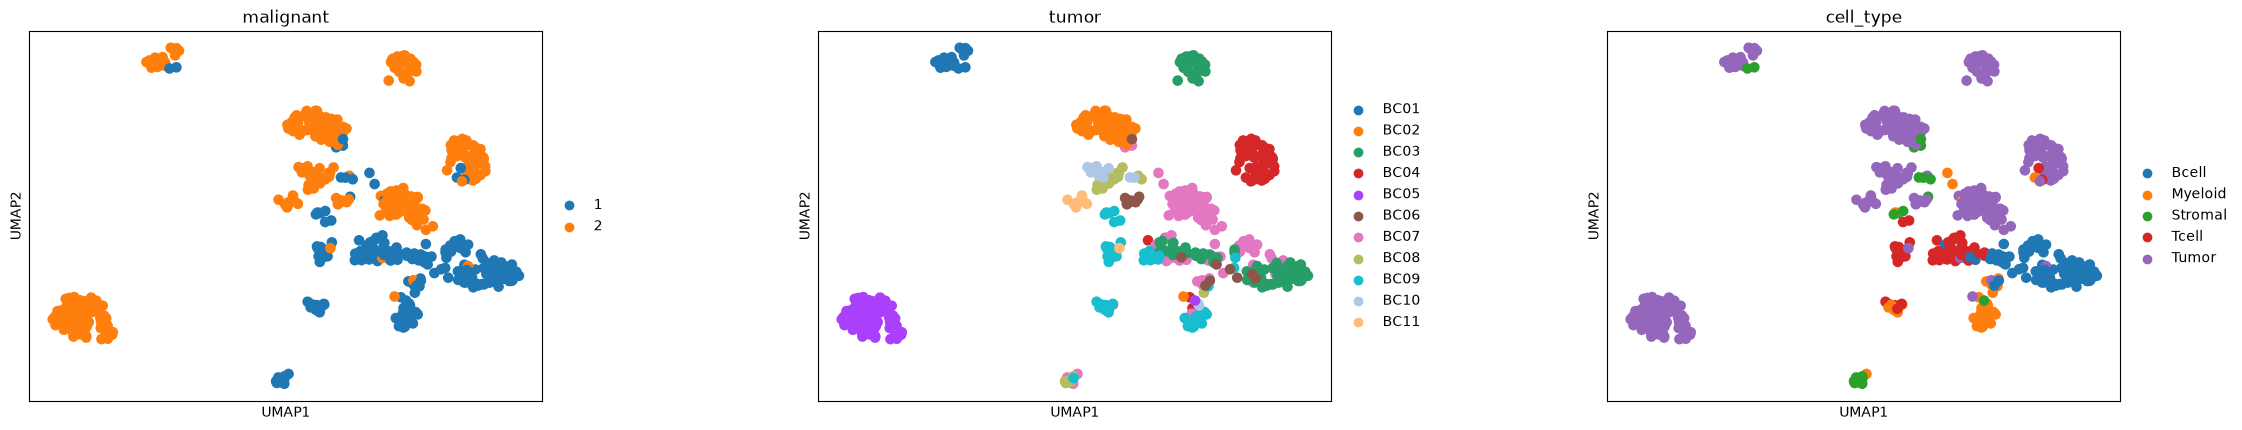

In [8]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

markers = ["PTPRC", "CD3E", "CD19", "CD14", "PECAM1", "COL1A1",
           "EPCAM", "KRT8", "KRT18", "KRT19", "ESR1", "ERBB2"]
markers = [g for g in markers if g in adata.var_names]
adata.var.loc[markers, "highly_variable"] = True
print(len(markers), adata.var["highly_variable"].sum())

adata_hv = adata[:, adata.var["highly_variable"]].copy()
sc.pp.pca(adata_hv, n_comps=50)
sc.pp.neighbors(adata_hv)
sc.tl.umap(adata_hv)
sc.pl.umap(adata_hv, color=["malignant", "tumor", "cell_type"], wspace=0.4)

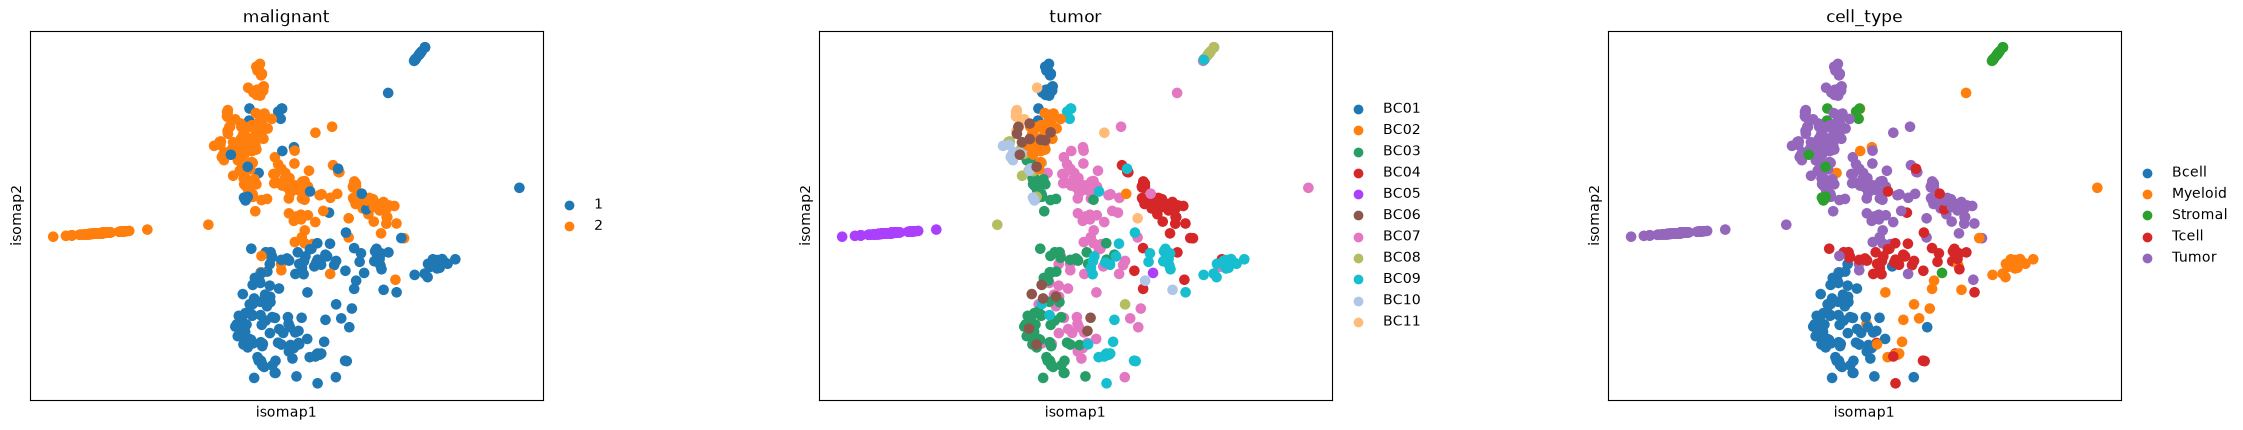

In [ ]:
from sklearn.manifold import Isomap

iso = Isomap(n_neighbors=10, n_components=2)
adata_hv.obsm["X_isomap"] = iso.fit_transform(adata_hv.obsm["X_pca"][:, :20])

sc.pl.embedding(adata_hv, basis="isomap", color=["malignant", "tumor", "cell_type"], wspace=0.4)

## 6. Train / test split

This dataset is small (about 500 cells), so I stratify by `malignant` instead of cell type
(some cell types may have too few cells to split).

In [13]:
train_idx, test_idx = train_test_split(adata_hv.obs_names, test_size=0.5,
                                       random_state=42, stratify=adata_hv.obs["malignant"])
train = adata_hv[train_idx].copy()
train = train[train.obs["malignant"] != "0"].copy()
test = adata_hv[test_idx].copy()
test = test[test.obs["malignant"] != "0"].copy()
y = (train.obs["malignant"] == "2").astype(int).values
y_test = (test.obs["malignant"] == "2").astype(int).values
print(len(train), "train cells,", len(test), "test cells")

257 train cells, 258 test cells


## 7. 16 candidate genes (training half only)

Top 8 cancer genes + top 8 normal genes, by Wilcoxon test. 16 genes = 16 qubits.

In [14]:
sc.tl.rank_genes_groups(train, groupby="malignant", method="wilcoxon")
top_cancer = sc.get.rank_genes_groups_df(train, group="2").head(8)
top_normal = sc.get.rank_genes_groups_df(train, group="1").head(8)
candidates = list(top_cancer["names"]) + list(top_normal["names"])
n = len(candidates)
candidates

['EPCAM',
 'KRT19',
 'KRT18',
 'KRT8',
 'ERBB2',
 'CLU',
 'VEGFA',
 'TPM1',
 'RGS1',
 'ALOX5AP',
 'PTPRC',
 'GPR183',
 'CD48',
 'IGKC',
 'CARD16',
 'IFI30']

## 8. Relevance (r) and redundancy (correlation)

In [15]:
expr = train[:, candidates].X
corr = np.corrcoef(expr.T)
r = np.array([abs(np.corrcoef(expr[:, i], y)[0, 1]) for i in range(n)])

for g, v in sorted(zip(candidates, r), key=lambda t: -t[1]):
    print(f"{g:10s} {v:.2f}")

print("\ncorrelation among the 8 cancer genes:")
print(np.round(corr[:8, :8], 2))

KRT18      0.78
EPCAM      0.76
KRT19      0.76
KRT8       0.76
RGS1       0.68
ALOX5AP    0.62
ERBB2      0.62
CLU        0.61
PTPRC      0.58
VEGFA      0.55
CD48       0.48
GPR183     0.46
CARD16     0.46
IGKC       0.44
TPM1       0.42
IFI30      0.38

correlation among the 8 cancer genes:
[[1.   0.65 0.77 0.75 0.66 0.54 0.56 0.44]
 [0.65 1.   0.8  0.8  0.44 0.62 0.45 0.42]
 [0.77 0.8  1.   0.84 0.58 0.67 0.51 0.42]
 [0.75 0.8  0.84 1.   0.55 0.64 0.51 0.45]
 [0.66 0.44 0.58 0.55 1.   0.42 0.47 0.35]
 [0.54 0.62 0.67 0.64 0.42 1.   0.36 0.43]
 [0.56 0.45 0.51 0.51 0.47 0.36 1.   0.33]
 [0.44 0.42 0.42 0.45 0.35 0.43 0.33 1.  ]]


## 9. The QUBO

Same as melanoma and head and neck: k = 2, α = 1, λ = 2.
I build two versions:
- `Q_abs`: redundancy = |correlation| (my first version)
- `Q`: redundancy = positive correlation only (opposite genes are not redundant)

In [17]:
k, alpha, lam = 2, 1.0, 2.0
const = lam * k**2

def build_Q(R):
    R = R.copy(); np.fill_diagonal(R, 0)
    Q = np.zeros((n, n))
    Q += alpha * R / 2
    Q += lam * (np.ones((n, n)) - np.eye(n))
    Q[np.diag_indices(n)] += -r + lam * (1 - 2 * k)
    return Q

Q_abs = build_Q(np.abs(corr))
Q = build_Q(np.clip(corr, 0, None))
print(Q.shape, const)

(16, 16) 8.0


## 10. Brute force over all 2^16 panels

Instead of a loop, I score all 65,536 bit strings at once.
Row b of `bits` is the bit string for the number b, with gene i = bit i
(the same order Qiskit uses, so I can compare with the Hamiltonian later).

In [18]:
bits = (np.arange(2**n)[:, None] >> np.arange(n)) & 1

def brute_force(Q):
    scores = np.einsum("bi,ij,bj->b", bits, Q, bits) + const
    b = scores.argmin()
    return b, scores[b], [candidates[i] for i in range(n) if bits[b, i]]

b_abs, s_abs, panel_abs = brute_force(Q_abs)
b_pos, s_pos, panel_qubo = brute_force(Q)
print("|R| QUBO:         ", panel_abs, round(s_abs, 3))
print("positive-only QUBO:", panel_qubo, round(s_pos, 3))

|R| QUBO:          ['ERBB2', 'PTPRC'] -0.939
positive-only QUBO: ['KRT18', 'RGS1'] -1.457


## 11. Grade the panels on the test half

Baselines: top 2 genes by relevance, and the single best gene alone
(to see how much the second gene actually adds).

In [19]:
def evaluate(panel, tr=train, te=test, ytr=y, yte=y_test):
    model = LogisticRegression(max_iter=1000).fit(tr[:, panel].X, ytr)
    return balanced_accuracy_score(yte, model.predict(te[:, panel].X))

order = np.argsort(-r)
panel_top2 = [candidates[order[0]], candidates[order[1]]]
panel_top1 = [candidates[order[0]]]

panels = {
    "QUBO (positive-only)": panel_qubo,
    "QUBO (|R|)": panel_abs,
    "top 2 by relevance": panel_top2,
    "best single gene": panel_top1,
}
for name, p in panels.items():
    print(f"{name:22s} {str(p):28s} {evaluate(p):.3f}")

QUBO (positive-only)   ['KRT18', 'RGS1']            0.916
QUBO (|R|)             ['ERBB2', 'PTPRC']           0.891
top 2 by relevance     ['KRT18', 'EPCAM']           0.912
best single gene       ['KRT18']                    0.880


## 12. Fairness check: 10 different splits

One split can be lucky. Here I re-split the cells 10 times (seeds 0 to 9)
and grade the same panels each time.
Caveat: the panels were chosen on the seed-42 training half, so this mostly checks
how stable the score is, not a fully fresh selection.

In [20]:
cells_all = adata_hv[adata_hv.obs["malignant"] != "0"].copy()
y_all = (cells_all.obs["malignant"] == "2").astype(int).values

ten = {name: [] for name in panels}
for seed in range(10):
    tr_i, te_i = train_test_split(np.arange(len(cells_all)), test_size=0.5,
                                  random_state=seed, stratify=y_all)
    tr, te = cells_all[tr_i], cells_all[te_i]
    for name, p in panels.items():
        ten[name].append(evaluate(p, tr, te, y_all[tr_i], y_all[te_i]))

for name, scores in ten.items():
    print(f"{name:22s} {np.mean(scores):.3f} ± {np.std(scores):.3f}")

QUBO (positive-only)   0.902 ± 0.012
QUBO (|R|)             0.872 ± 0.016
top 2 by relevance     0.905 ± 0.012
best single gene       0.897 ± 0.011


## 13. QAOA: cost Hamiltonian

x = (1 − Z)/2, so Z = −1 means "gene is in the panel".
Every gene becomes a Z term and every pair a ZZ term (16 + 120 = 136 terms).
Check: the lowest-energy bit string must be the brute-force answer.

In [21]:
terms, offset = [], const
for i in range(n):
    terms.append(("Z", [i], -Q[i, i] / 2))
    offset += Q[i, i] / 2
    for j in range(n):
        if i != j:
            terms.append(("ZZ", [i, j], Q[i, j] / 4))
            terms.append(("Z", [i], -Q[i, j] / 4))
            terms.append(("Z", [j], -Q[i, j] / 4))
            offset += Q[i, j] / 4

H = SparsePauliOp.from_sparse_list(terms, num_qubits=n).simplify()
diag = H.to_matrix(sparse=True).diagonal().real
best = int(np.argmin(diag))

print(len(H), "terms")
print("lowest energy:", round(diag[best] + offset, 3), " brute force:", round(s_pos, 3))
print("genes:", [candidates[i] for i in range(n) if (best >> i) & 1])
print("matches brute force:", best == b_pos)

136 terms
lowest energy: -1.457  brute force: -1.457
genes: ['KRT18', 'RGS1']
matches brute force: True


## 14. QAOA p = 1: angle grid

The fast way: one angle pair at a time, and average energy = probabilities × energies.
25 × 25 = 625 points, about 2 minutes.

In [22]:
sizes = bits.sum(axis=1)
random_energy = diag.mean() + offset

def run(qc, angles):
    p = Statevector(qc.assign_parameters(angles)).probabilities()
    return p @ diag + offset, p

qc1 = transpile(QAOAAnsatz(H, reps=1), basis_gates=["h", "rz", "rx", "cx"])
betas = np.linspace(0, np.pi / 2, 25)
gammas = np.linspace(0, 0.5, 25)
energy1 = np.zeros((25, 25))

t = time.time()
for a, g in enumerate(gammas):
    for bb, bt in enumerate(betas):
        energy1[a, bb] = run(qc1, [bt, g])[0]
a, bb = np.unravel_index(energy1.argmin(), energy1.shape)
angles1 = [betas[bb], gammas[a]]
e1, probs1 = run(qc1, angles1)

print(f"{time.time() - t:.0f} s")
print("best avg energy:", round(e1, 3), " β =", round(betas[bb], 3), " γ =", round(gammas[a], 3))
print("P(best panel):", round(probs1[best], 5))
print("P(2 genes):", round(probs1[sizes == 2].sum(), 4))

95 s
best avg energy: 56.414  β = 0.327  γ = 0.167
P(best panel): 0.00016
P(2 genes): 0.0193


## 15. QAOA p = 2: COBYLA

4 angles (β0, β1, γ0, γ1), starting from the p = 1 angles used twice.

In [23]:
qc2 = transpile(QAOAAnsatz(H, reps=2), basis_gates=["h", "rz", "rx", "cx"])
start2 = [angles1[0], angles1[0], angles1[1], angles1[1]]
res2 = minimize(lambda x: run(qc2, x)[0], start2, method="COBYLA", options={"maxiter": 200})
e2, probs2 = run(qc2, res2.x)

print("best avg energy:", round(e2, 3), " angles:", res2.x.round(3))
print("P(best panel):", round(probs2[best], 5))
print("P(2 genes):", round(probs2[sizes == 2].sum(), 4))

best avg energy: 49.971  angles: [0.282 0.221 0.16  1.252]
P(best panel): 0.00131
P(2 genes): 0.1159


## 16. QAOA p = 3 (new)

6 angles (β0, β1, β2, γ0, γ1, γ2). I start from the p = 2 angles and repeat the last layer.

In [24]:
qc3 = transpile(QAOAAnsatz(H, reps=3), basis_gates=["h", "rz", "rx", "cx"])
b0, b1, g0, g1 = res2.x
start3 = [b0, b1, b1, g0, g1, g1]
res3 = minimize(lambda x: run(qc3, x)[0], start3, method="COBYLA", options={"maxiter": 300})
e3, probs3 = run(qc3, res3.x)

print("best avg energy:", round(e3, 3), " angles:", res3.x.round(3))
print("P(best panel):", round(probs3[best], 5))
print("P(2 genes):", round(probs3[sizes == 2].sum(), 4))

best avg energy: 46.88  angles: [0.29  0.21  0.22  0.16  1.245 2.273]
P(best panel): 0.00086
P(2 genes): 0.1109


## 17. Summary

In [25]:
qaoa_table = pd.DataFrame({
    "avg energy": [random_energy, e1, e2, e3, diag[best] + offset],
    "P(best panel)": [1 / 2**n, probs1[best], probs2[best], probs3[best], 1],
    "P(2 genes)": [(sizes == 2).mean(), probs1[sizes == 2].sum(), probs2[sizes == 2].sum(),
                   probs3[sizes == 2].sum(), 1],
}, index=["random", "QAOA p = 1", "QAOA p = 2", "QAOA p = 3", "exact"]).round(5)

accuracy_table = pd.DataFrame({
    "panel": [str(p) for p in panels.values()],
    "balanced accuracy (seed 42)": [round(evaluate(p), 3) for p in panels.values()],
    "10 splits": [f"{np.mean(s):.3f} ± {np.std(s):.3f}" for s in ten.values()],
}, index=list(panels.keys()))

display(accuracy_table)
display(qaoa_table)

,panel,balanced accuracy (seed 42),10 splits
QUBO (positive-only),"['KRT18', 'RGS1']",0.916,0.902 ± 0.012
QUBO (|R|),"['ERBB2', 'PTPRC']",0.891,0.872 ± 0.016
top 2 by relevance,"['KRT18', 'EPCAM']",0.912,0.905 ± 0.012
best single gene,['KRT18'],0.880,0.897 ± 0.011


,avg energy,P(best panel),P(2 genes)
random,82.26122,0.00002,0.00183
QAOA p = 1,56.41393,0.00016,0.01934
QAOA p = 2,49.97134,0.00131,0.11587
QAOA p = 3,46.87955,0.00086,0.11089
exact,-1.45716,1.00000,1.00000
